In [1]:
import os, sys, time
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import shapely.geometry
import shapely.errors
import fiona
import rasterio
import rasterio.mask
import rasterio.features
import affine

from matplotlib import pyplot 
from matplotlib import cm

from collections import OrderedDict # for output schema

import rtree
import math
import csv

/srv/sw/conda.evns/fim3/lib/python3.7/site-packages/geopandas/_compat.py:110: UserWarning: The Shapely GEOS version (3.8.0-CAPI-1.13.1 ) is incompatible with the GEOS version PyGEOS was compiled with (3.8.1-CAPI-1.13.3). Conversions between both will be slow.
  shapely_geos_version, geos_capi_version_string


# test techniques to fix the short reach issue of cahaba/src/split_flows.py

cahaba code uses gpd.overlay (how='union') to split flowlines using lake polygons, whic creates a lot of small segments due to mis-alignment b/w a lake polygon, which is the rough boundary of a lake, and dem-derived flowlines.

the fix attempts to split a flowline that goes through a lake into only three parts: the part connecting to the lake with an inlet point (the beginning), the part within the lake, and the part leaving the lake via the outlet point.

idea:
- gpd.overlay (how = 'identity') to split flowline into a set of segments. all of them are part of the flowline
- check if the overlay result itself can determine the beginning segment and the leaving segment. that is one way
- but a more straightforward way is: the beginning and the leaving segment only has one end overlapping with another segment while all other segments have two

boundary cases:
- there is no beginning or leaving or both parts

## multi-polygon example

<AxesSubplot:>

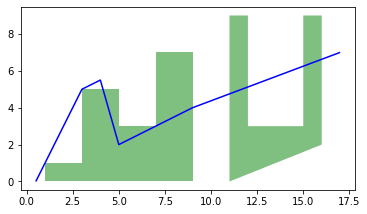

In [2]:
poly1 = shapely.geometry.Polygon([(1,0), (1,1), (3,1), (3,5), (5,5), (5,3), (7,3), (7,7), (9,7), (9,0)])
poly2 = shapely.geometry.Polygon([(11,0), (11,9), (12, 9), (12, 3), (13, 3), (15, 3), (15,9), (16,9), (16,2)])
flowline = shapely.geometry.LineString([(0.5,0), (3,5), (4,5.5), (5,2), (7,3), (9,4), (17,7)])
gdf_flow = gpd.GeoDataFrame({'geometry': gpd.GeoSeries([flowline]), 'flow':[1]}) 
gdf_lake = gpd.GeoDataFrame({'geometry': gpd.GeoSeries([poly1, poly2]), 'lake':[1,2]}) 
ax = gdf_flow.plot(color='blue')
gdf_lake.plot(ax=ax, color='green', alpha=0.5)

In [62]:
gdf_lake.iloc[1]['lake']

2

In [4]:
type(gdf_lake.geometry)

geopandas.geoseries.GeoSeries

## real example

In [22]:
ddir = '/srv/test/cahaba/ornl'
flowwkt_fn = ddir + '/' + 'bugfix-tiny-split_flowline.wkt'
lakewkt_fn = ddir + '/' + 'bugfix-tiny-split_lake.wkt'

In [23]:
with open(flowwkt_fn, 'r') as f_flowwkt:
    flowwkt = f_flowwkt.read()
    flowline = shapely.wkt.loads(flowwkt)
with open(lakewkt_fn, 'r') as f_lakewkt:
    lakewkt = f_lakewkt.read()
    lakepoly = shapely.wkt.loads(lakewkt)

In [24]:
gdf_flow = gpd.GeoDataFrame({'geometry': gpd.GeoSeries([flowline]), 'flow':[1]}) 
gdf_lake = gpd.GeoDataFrame({'geometry': gpd.GeoSeries([lakepoly]), 'lake':[1]}) 

<AxesSubplot:>

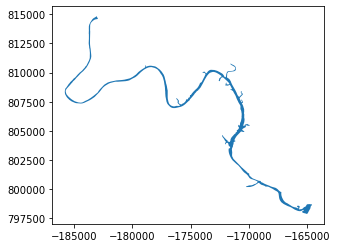

In [26]:
gdf_lake.plot()

<AxesSubplot:>

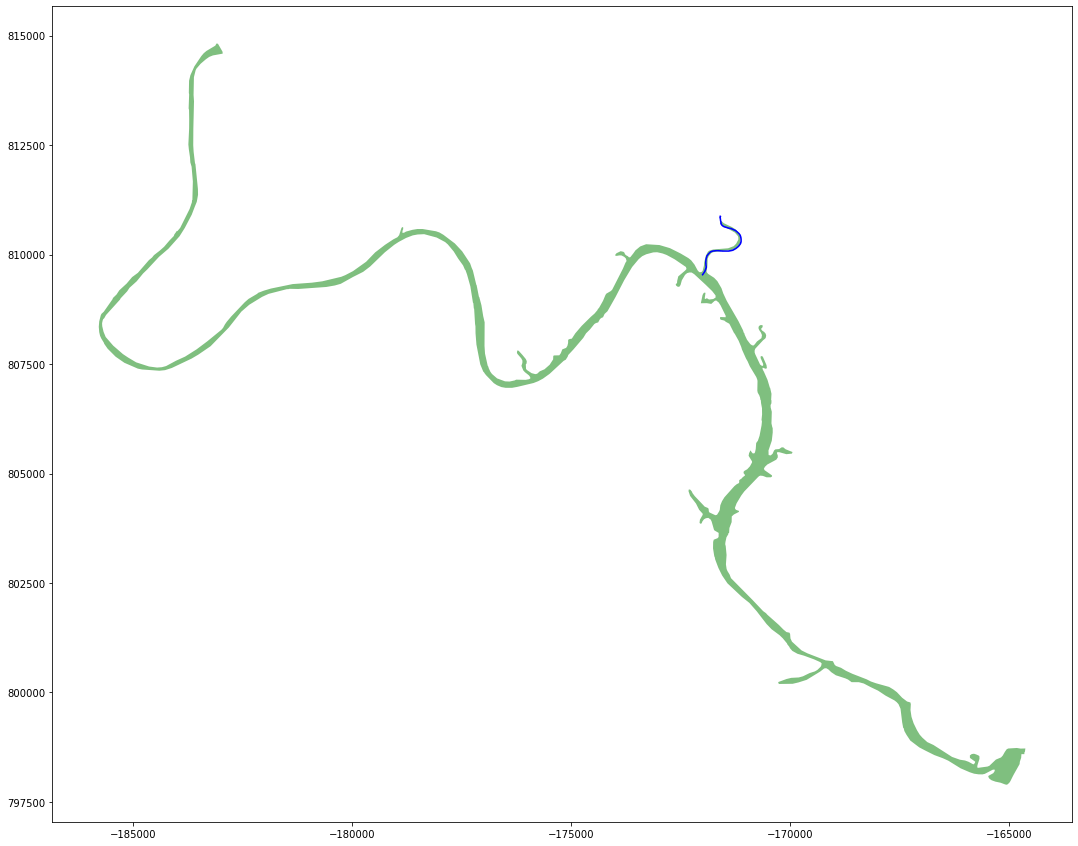

In [27]:
ax = gdf_flow.plot(color='blue', figsize=(20,15))
gdf_lake.plot(ax=ax, color='green', alpha=0.5)

In [28]:
gdf_flow

,geometry,flow
0,"LINESTRING (-172001.112 809526.272, -171998.05...",1


In [64]:
gdf_ol_ident = gpd.overlay(gdf_flow, gdf_lake, how='identity')
print('identity overlap generated', gdf_ol_ident.shape[0], 'segments')
gdf_ol_ident = gdf_ol_ident.loc[~gdf_ol_ident.is_empty, :]
print('after removing empty geom, there are', gdf_ol_ident.shape[0], 'segments')
gdf_ol_ident = gdf_ol_ident.explode().reset_index(drop=True)
num_edges = gdf_ol_ident.shape[0]
if num_edges == 1:
    print('No need to split')

identity overlap generated 3 segments
after removing empty geom, there are 3 segments


In [65]:
gdf_ol_ident

,flow,lake,geometry
0,1.0,1.0,"LINESTRING (4.14286 5.00000, 5.00000 2.00000, ..."
1,1.0,1.0,"LINESTRING (7.00000 3.00000, 9.00000 4.00000)"
2,1.0,2.0,"LINESTRING (11.00000 4.75000, 12.00000 5.12500)"
3,1.0,2.0,"LINESTRING (15.00000 6.25000, 16.00000 6.62500)"
4,1.0,NaN,"LINESTRING (0.50000 0.00000, 1.00000 1.00000)"
5,1.0,NaN,"LINESTRING (1.00000 1.00000, 3.00000 5.00000)"
6,1.0,NaN,"LINESTRING (3.00000 5.00000, 4.00000 5.50000, ..."
7,1.0,NaN,"LINESTRING (9.00000 4.00000, 11.00000 4.75000)"
8,1.0,NaN,"LINESTRING (12.00000 5.12500, 15.00000 6.25000)"
9,1.0,NaN,"LINESTRING (16.00000 6.62500, 17.00000 7.00000)"


In [16]:
ax = gdf_ol_ident.plot(cmap='Set1', figsize=(10,8)) # red,darkgrey w/ red means the first row (in lake)
gdf_lake.plot(ax=ax, color='grey', alpha=0.2)
#gdf_lake.plot(ax=ax, facecolor='none', edgecolor='k')
#gdf_flow.plot(ax=ax, facecolor='none', edgecolor='k')

NameError: name 'gdf_ol_ident' is not defined

## build end point hash & mark segment position (in/out of lake)

In [67]:
node2edges = {}
inlake = np.zeros(num_edges, dtype=np.int16)
for i, (flow, lake, geom) in gdf_ol_ident.iterrows():
    for p in [geom.coords[0], geom.coords[-1]]:
        if not p in node2edges:
            node2edges[p] = [i]
        else:
            node2edges[p].append(i)
    if not pd.isna(lake): # part of lake
        inlake[i] = lake # lake id needs to >0

In [68]:
node2edges

{(4.142857142857143, 5.0): [0, 6],
 (7.0, 3.0): [0, 1],
 (9.0, 4.0): [1, 7],
 (11.0, 4.75): [2, 7],
 (12.0, 5.125): [2, 8],
 (15.0, 6.25): [3, 8],
 (16.0, 6.625): [3, 9],
 (0.5, 0.0): [4],
 (1.0, 1.0): [4, 5],
 (3.0, 5.0): [5, 6],
 (17.0, 7.0): [9]}

In [69]:
inlake

array([1, 1, 2, 2, 0, 0, 0, 0, 0, 0], dtype=int16)

## reorder segments from flowline start to end

In [70]:
h_edges = np.zeros(num_edges, dtype=np.int8) # record if an edge has been visited
inlet = flowline.coords[0]
inlets = {inlet} # start from flowline's first end point
ordered_edges = []
for i in range(num_edges):
    edges = node2edges[inlet]
    for edge in edges:
        if h_edges[edge] == 0: # not visited before
            ordered_edges.append(edge) # add segment to ordered list
            h_edges[edge] = 1 # visited
            geom = gdf_ol_ident.iloc[edge]['geometry']
            outlet = None
            for p in [geom.coords[0], geom.coords[-1]]:
                if not p in inlets: # outlet, i.e., next inlet
                    outlet = p
                    break
            if outlet is None:
                print('ERROR could not find outlet')
            else:
                inlet = outlet
                inlets.add(inlet)

In [71]:
ordered_edges

[4, 5, 6, 0, 1, 7, 2, 8, 3, 9]

In [72]:
inlake

array([1, 1, 2, 2, 0, 0, 0, 0, 0, 0], dtype=int16)

In [73]:
[inlake[i] for i in ordered_edges]

[0, 0, 0, 1, 1, 0, 2, 0, 2, 0]

In [38]:
# single lake polygon
# BUG: did not process cosecutive 0's or 1's (touches)
flow_splits = None
first_isoutside, last_isoutside = isoutside[ordered_edges[0]], isoutside[ordered_edges[-1]]
if (not first_isoutside) and (not last_isoutside): # both inside of the lake
    flow_splits = [flowline] # do nothing
elif first_isoutside and last_isoutside: # both outside
    if num_edges < 3: # num_edges == 1, nothing to do
        flow_splits = [flowline]
    else: # 3 parts
        combined_seg = [pnt for geom in gdf_ol_ident.iloc[ordered_edges[1:-1]]['geometry'] for pnt in geom.coords[:-1]]
        combined_seg.append(gdf_ol_ident.iloc[ordered_edges[-1]]['geometry'].coords[0])
        flow_splits = [gdf_ol_ident.iloc[ordered_edges[0]]['geometry'],
                      shapely.geometry.LineString(combined_seg),
                      gdf_ol_ident.iloc[ordered_edges[-1]]['geometry']]
elif first_isoutside and not last_isoutside: # two parts: out-in: first seg + the rest
    combined_seg = [pnt for geom in gdf_ol_ident.iloc[ordered_edges[1:]]['geometry'] for pnt in geom.coords[:-1]]
    combined_seg.append(gdf_ol_ident.iloc[ordered_edges[-1]]['geometry'].coords[-1])
    flow_splits = [gdf_ol_ident.iloc[ordered_edges[0]]['geometry'],
                      shapely.geometry.LineString(combined_seg)]
else: # not first_isoutside and last_isoutside: #two parts: in-out: 1st to the 2nd to the last + the last
    combined_seg = [pnt for geom in gdf_ol_ident.iloc[ordered_edges[:-1]]['geometry'] for pnt in geom.coords[:-1]]
    combined_seg.append(gdf_ol_ident.iloc[ordered_edges[-1]]['geometry'].coords[0])
    flow_splits = [shapely.geometry.LineString(combined_seg),
                  gdf_ol_ident.iloc[ordered_edges[-1]]['geometry']]

In [84]:
# label lake id to consecutive segments that belong to that lake.
# observations: let's add a virtual lake id to the beginning -1
# 1. any lake seg begins with that lake id. no zeros in front (otherwise it is not the beginning)
# 2. any lake subseq ends with that lake id (zero cannot be at the end)
# 3. a lake subseq regular expression x(0*x+)*0*y
def connect_seg_by_lake(lakeseq0):
    lakeseq = lakeseq0.copy()
    curlake = -1 # suppose we start from late id -1
    numout = 0 # num of segments outside of the lake but need to be label with this lake id
    for i in range(len(lakeseq)): # now look next
        l = lakeseq[i]
        if l == 0: # find more outside edges
            numout += 1
        elif l == curlake: # belong to the same lake
            for j in range(numout): # fill in-between with the same lake id
                lakeseq[i-j-1] = curlake
            numout = 0 # reset counter
        else: # a new lake. already marked curlake range, outside segs are marked, too. just restart
            curlake = l
            numout = 0
            
    return lakeseq

In [85]:
lakeseq = [inlake[i] for i in ordered_edges]
newseq = connect_seg_by_lake(lakeseq)
print('before:', lakeseq)
print('after: ', newseq)

before: [0, 0, 0, 1, 1, 0, 2, 0, 2, 0]
after:  [0, 0, 0, 1, 1, 0, 2, 2, 2, 0]


In [77]:
lakeseq = [0, 0, 1, 0, 0, 0, 1, 0, 0, 2, 0, 2, 0, 2, 2, 0, 0, 2]
newseq = connect_seg_by_lake(lakeseq)
print('before:', lakeseq)
print('after: ', newseq)

before: [0, 0, 1, 0, 0, 0, 1, 0, 0, 2, 0, 2, 0, 2, 2, 0, 0, 2]
after:  [0, 0, 1, 1, 1, 1, 1, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2]


In [78]:
lakeseq = [4, 0, 0, 0, 1, 0, 0, 2, 0, 2, 0, 2, 2, 0, 0, 2, 0, 0]
newseq = connect_seg_by_lake(lakeseq)
print('before:', lakeseq)
print('after: ', newseq)

before: [4, 0, 0, 0, 1, 0, 0, 2, 0, 2, 0, 2, 2, 0, 0, 2, 0, 0]
after:  [4, 0, 0, 0, 1, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0]


In [79]:
lakeseq = []
newseq = connect_seg_by_lake(lakeseq)
print('before:', lakeseq)
print('after: ', newseq)

before: []
after:  []


In [80]:
lakeseq = [0]
newseq = connect_seg_by_lake(lakeseq)
print('before:', lakeseq)
print('after: ', newseq)

before: [0]
after:  [0]


In [81]:
lakeseq = [1]
newseq = connect_seg_by_lake(lakeseq)
print('before:', lakeseq)
print('after: ', newseq)

before: [1]
after:  [1]


In [82]:
lakeseq = [1,2,3,4,5]
newseq = connect_seg_by_lake(lakeseq)
print('before:', lakeseq)
print('after: ', newseq)

before: [1, 2, 3, 4, 5]
after:  [1, 2, 3, 4, 5]


In [83]:
lakeseq = [0,1,1,0,1,0,0,1]
newseq = connect_seg_by_lake(lakeseq)
print('before:', lakeseq)
print('after: ', newseq)

before: [0, 1, 1, 0, 1, 0, 0, 1]
after:  [0, 1, 1, 1, 1, 1, 1, 1]


In [110]:
# now merge segments into line geometry 
lakeseq = [inlake[i] for i in ordered_edges]
newseq = connect_seg_by_lake(lakeseq)
nolake = -999

newseq += [-1] # to handle the end
lakeids = []
flow_splits = []
start = 0
lakeid = newseq[0]
for i in range(len(newseq)):
    if newseq[i] != lakeid: # merge prev segments
        lakeids.append(lakeid)
        combined_seg = [pnt for geom in gdf_ol_ident.iloc[ordered_edges[start:i]]['geometry'] for pnt in geom.coords[:-1]]
        combined_seg.append(gdf_ol_ident.iloc[ordered_edges[i-1]]['geometry'].coords[-1])
        flow_splits.append(shapely.geometry.LineString(combined_seg))
        start = i
        lakeid = newseq[i]

In [111]:
lakeids

[0, 1, 0, 2, 0]

In [39]:
first_isoutside, last_isoutside

(0, 1)

In [40]:
flow_splits[0].coords[-1], flow_splits[1].coords[0]

((-171581.22761931468, 810772.3929628626),
 (-171581.22761931468, 810772.3929628626))

## AUTOMATED

In [126]:
# when a flowline goes through an overlay polygon,
# the intention is to keep the segment in the polygon 
# as a single segment, i.e., to split the input
# flowline to (out, in, out).
# BUG: does not handle the case in which line touches polygons (consecutive 0's, 1's)
def split_through_polygon(flowline, ol_polygon):
    # use geopandas overlay's identity method to chop flowline
    gdf_flow = gpd.GeoDataFrame({'geometry': gpd.GeoSeries([flowline]), 'flow':[1]})
    gdf_lake = gpd.GeoDataFrame({'geometry': gpd.GeoSeries([ol_polygon]), 'lake':[1]})
    gdf_ol_ident = gpd.overlay(gdf_flow, gdf_lake, how='identity')
    print('identity overlap generated', gdf_ol_ident.shape[0], 'segments')
    gdf_ol_ident = gdf_ol_ident.loc[~gdf_ol_ident.is_empty, :]
    print('after removing empty geom, there are', gdf_ol_ident.shape[0], 'segments')
    gdf_ol_ident = gdf_ol_ident.explode().reset_index(drop=True)
    num_edges = gdf_ol_ident.shape[0]
    if num_edges == 1:
        print('No need to split')
        return [flowline]

    # hash segment end points and segments each point is connected to
    node2edges = {}
    isoutside = np.zeros(num_edges, dtype=np.int8)
    for i, (flow, lake, geom) in gdf_ol_ident.iterrows():
        for p in [geom.coords[0], geom.coords[-1]]:
            if not p in node2edges:
                node2edges[p] = [i]
            else:
                node2edges[p].append(i)
        if pd.isna(lake): # not part of lake, i.e., outside
            isoutside[i] = 1

    # order segments
    h_edges = np.zeros(num_edges, dtype=np.int8) # record if an edge has been visited
    inlet = flowline.coords[0]
    inlets = {inlet} # start from flowline's first end point
    ordered_edges = []
    for i in range(num_edges):
        edges = node2edges[inlet]
        for edge in edges:
            if h_edges[edge] == 0: # not visited before
                ordered_edges.append(edge) # add segment to ordered list
                h_edges[edge] = 1 # visited
                geom = gdf_ol_ident.iloc[edge]['geometry']
                outlet = None
                for p in [geom.coords[0], geom.coords[-1]]:
                    if not p in inlets: # outlet, i.e., next inlet
                        outlet = p
                        break
                if outlet is None:
                    print('ERROR could not find outlet')
                else:
                    inlet = outlet
                    inlets.add(inlet)
    print('isoutside of lake:', [isoutside[i] for i in ordered_edges])
    
    # create splits
    flow_splits = None
    first_isoutside, last_isoutside = isoutside[ordered_edges[0]], isoutside[ordered_edges[-1]]
    if (not first_isoutside) and (not last_isoutside): # both inside of the lake
        flow_splits = [flowline] # do nothing
    elif first_isoutside and last_isoutside: # both outside
        if num_edges < 3: # num_edges == 1, nothing to do
            flow_splits = [flowline]
        else: # 3 parts
            combined_seg = [pnt for geom in gdf_ol_ident.iloc[ordered_edges[1:-1]]['geometry'] for pnt in geom.coords[:-1]]
            combined_seg.append(gdf_ol_ident.iloc[ordered_edges[-1]]['geometry'].coords[0])
            flow_splits = [gdf_ol_ident.iloc[ordered_edges[0]]['geometry'],
                          shapely.geometry.LineString(combined_seg),
                          gdf_ol_ident.iloc[ordered_edges[-1]]['geometry']]
    elif first_isoutside and not last_isoutside: # two parts: out-in: first seg + the rest
        combined_seg = [pnt for geom in gdf_ol_ident.iloc[ordered_edges[1:]]['geometry'] for pnt in geom.coords[:-1]]
        combined_seg.append(gdf_ol_ident.iloc[ordered_edges[-1]]['geometry'].coords[-1])
        flow_splits = [gdf_ol_ident.iloc[ordered_edges[0]]['geometry'],
                          shapely.geometry.LineString(combined_seg)]
    else: # not first_isoutside and last_isoutside: #two parts: in-out: 1st to the 2nd to the last + the last
        combined_seg = [pnt for geom in gdf_ol_ident.iloc[ordered_edges[:-1]]['geometry'] for pnt in geom.coords[:-1]]
        combined_seg.append(gdf_ol_ident.iloc[ordered_edges[-1]]['geometry'].coords[0])
        flow_splits = [shapely.geometry.LineString(combined_seg),
                      gdf_ol_ident.iloc[ordered_edges[-1]]['geometry']]
    
    return flow_splits

In [42]:
# label lake id to consecutive segments that belong to that lake.
# observations: let's add a virtual lake id to the beginning -1
# 1. any lake seg begins with that lake id. no zeros in front (otherwise it is not the beginning)
# 2. any lake subseq ends with that lake id (zero cannot be at the end)
# 3. a lake subseq regular expression x(0*x+)*0*y
def connect_seg_by_lake(lakeseq0):
    lakeseq = lakeseq0.copy()
    curlake = -1 # suppose we start from late id -1
    numout = 0 # num of segments outside of the lake but need to be label with this lake id
    for i in range(len(lakeseq)): # now look next
        l = lakeseq[i]
        if l == 0: # find more outside edges
            numout += 1
        elif l == curlake: # belong to the same lake
            for j in range(numout): # fill in-between with the same lake id
                lakeseq[i-j-1] = curlake
            numout = 0 # reset counter
        else: # a new lake. already marked curlake range, outside segs are marked, too. just restart
            curlake = l
            numout = 0
            
    return lakeseq

# when a flowline goes through an overlay of multiple polygons,
# the intention is to keep the segment in any polygon 
# as a single segment.
# assumpution: polygons do not overlap
def split_through_polygons(flowline, ol_polygons, ol_lakes):
    # use geopandas overlay's identity method to chop flowline
    gdf_flow = gpd.GeoDataFrame({'geometry': gpd.GeoSeries([flowline]), 'flow':[1]})
    gdf_lake = gpd.GeoDataFrame({'geometry': gpd.GeoSeries(ol_polygons), 'lake':ol_lakes})
    gdf_ol_ident = gpd.overlay(gdf_flow, gdf_lake, how='identity')
    #print('identity overlap generated', gdf_ol_ident.shape[0], 'segments')
    gdf_ol_ident = gdf_ol_ident.loc[~gdf_ol_ident.is_empty, :]
    #print('after removing empty geom, there are', gdf_ol_ident.shape[0], 'segments')
    gdf_ol_ident = gdf_ol_ident.explode().reset_index(drop=True)
    num_edges = gdf_ol_ident.shape[0]
    if num_edges == 1: # no split, accelerate by skipping the rest
        lakeid = gdf_ol_ident.iloc[0]['lake']
        if pd.isna(lakeid):
            lakeid = -999
        return [flowline], [lakeid]

    # hash segment end points and segments each point is connected to
    node2edges = {}
    inlake = np.zeros(num_edges, dtype=np.int32)
    for i, (flow, lake, geom) in gdf_ol_ident.iterrows():
        for p in [geom.coords[0], geom.coords[-1]]:
            if not p in node2edges:
                node2edges[p] = [i]
            else:
                node2edges[p].append(i)
        if not pd.isna(lake): # part of lake
            inlake[i] = lake # lake id needs to >0
    
    # order segments
    h_edges = np.zeros(num_edges, dtype=np.int8) # record if an edge has been visited
    inlet = flowline.coords[0]
    inlets = {inlet} # start from flowline's first end point
    ordered_edges = []
    for i in range(num_edges):
        edges = node2edges[inlet]
        for edge in edges:
            if h_edges[edge] == 0: # not visited before
                ordered_edges.append(edge) # add segment to ordered list
                h_edges[edge] = 1 # visited
                geom = gdf_ol_ident.iloc[edge]['geometry']
                outlet = None
                for p in [geom.coords[0], geom.coords[-1]]:
                    if not p in inlets: # outlet, i.e., next inlet
                        outlet = p
                        break
                if outlet is None:
                    print('ERROR could not find outlet')
                else:
                    inlet = outlet
                    inlets.add(inlet)

    # create splits
    lakeseq = [inlake[i] for i in ordered_edges]
    newseq = connect_seg_by_lake(lakeseq) # label consecutive segmetns using their lake ids
    #print('lakeseq', lakeseq)
    #print('lakeseq (labeled)', newseq)
    # now merge segments into line geometry 
    newseq += [-1] # to handle the end
    lakeids = []
    flow_splits = []
    start = 0
    lakeid = newseq[0]
    for i in range(len(newseq)):
        if newseq[i] != lakeid: # merge prev segments
            lakeids.append(lakeid)
            combined_seg = [pnt for geom in gdf_ol_ident.iloc[ordered_edges[start:i]]['geometry'] for pnt in geom.coords[:-1]]
            combined_seg.append(gdf_ol_ident.iloc[ordered_edges[i-1]]['geometry'].coords[-1])
            flow_splits.append(shapely.geometry.LineString(combined_seg))
            start = i
            lakeid = newseq[i]

    return flow_splits, lakeids # lakeid == 0 if outside of the lake

# construct r-tree for tiles
def construct_lakes_rtree(lakes, fn_lakeid):
    def generate_items():
        index = 0
        for i, row in lakes.iterrows():
            box = row['geometry'].bounds
            yield (index, box, (i, row[fn_lakeid], row['geometry']))
            index += 1
    return rtree.index.Index(generate_items())

def split_flows_on_lakes(flows, lakes, fn_lakeid, fn_new_lakeid):
    if lakes is None or len(lakes) <= 0: # no need to split
        flows[fn_new_lakeid] = -999 # no lake
        return flows
    # build rtree on lake bboxes
    searchtree = construct_lakes_rtree(lakes, fn_lakeid)
    # split each flowline on lakes
    l_flows = []
    l_lakeids = []
    count_rtree_hits = 0
    count_splits = 0
    count_split_flowlines = 0
    count_flowlines_tosplit = 0
    for i, row in flows.iterrows():
        flowline = row['geometry']
        hits = searchtree.intersection(flowline.bounds, objects='raw')
        ol_lakes = []
        ol_polygons = []
        for j, lakeid, lakegeom in hits:
            ol_lakes.append(lakeid)
            ol_polygons.append(lakegeom)
        if len(ol_polygons) == 0: # no hits
            l_flows += [flowline]
            l_lakeids += [-999]
            continue
        count_rtree_hits += len(ol_polygons)
        count_flowlines_tosplit += 1
        # split flows by lake polygons
        flow_splits, lakeids = split_through_polygons(flowline, ol_polygons, ol_lakes)
        lakeids = [-999 if l==0 else l for l in lakeids]
        l_flows += flow_splits
        l_lakeids += lakeids
        if len(flow_splits)>1:
            count_splits += len(flow_splits)
            count_split_flowlines += 1
    print('split_flows_on_lakes: rtree efficiency:', 'space:', len(flows), 'x', len(lakes), '=', len(flows)*len(lakes),
         'match rate:', count_rtree_hits, '/', len(flows)*len(lakes), '=', count_rtree_hits/(len(flows)*len(lakes)))
    print('split_flows_on_lakes: split stats:', 'flowlines_considered', count_flowlines_tosplit,
         'split_ratio:', count_splits, '/', count_split_flowlines, '=', count_splits/count_split_flowlines )
    print('split_flows_on_lakes: preserved stats:', 'not_touched:',  (len(flows) - count_flowlines_tosplit),
          'no_split:', count_flowlines_tosplit - count_split_flowlines)
    return gpd.GeoDataFrame({'geometry': l_flows, fn_new_lakeid: l_lakeids}, crs=flows.crs, geometry='geometry')

# TEST ZONE

In [40]:
%%time
# test split_flows_on_lakes()
from os.path import isfile

#ddir = '/home/yxl/test/fim3/tmp/12090205'
ddir = '/home/yxl/test/fim3/cache/outputs/12100202/12100202' # flowline no bound bug
odir = '/home/yxl/test/fim3/tmp/test_split_flows'
flows_filename = ddir + '/demDerived_reaches.shp'
lakes_filename = ddir + '/nwm_lakes_proj_subset.gpkg'
wbd8_clp_filename = ddir + '/wbd8_clp.gpkg'

FIM_ID = 'fimid'
wbd8 = gpd.read_file(wbd8_clp_filename)
wbd8 = wbd8.filter(items=[FIM_ID, 'geometry'])
wbd8 = wbd8.set_index(FIM_ID)
print('wbd8', wbd8.columns)

flows = gpd.read_file(flows_filename)
flows = flows.explode()
flows = flows.to_crs(wbd8.crs)
print('flowlines:', len(flows), 'attributes:', flows.columns)

flows2 = gpd.overlay(flows, wbd8, how='union').explode().reset_index(drop=True)
print('flows U wbd8:', len(flows2), 'attributes:', flows.columns)
flows2 = flows2.loc[~flows2.is_empty,:] # this has to be done first. 12100202 overlay with wbd8 creates empty geometry
print('flows U wbd8 after empty removal:', len(flows2))

if isfile(lakes_filename):
    lakes = gpd.read_file(lakes_filename)
else:
    lakes = None
if not lakes is None:
    lakes = lakes.filter(items=['newID', 'geometry'])
    print('lakes:', lakes.columns)
    flows3 = split_flows_on_lakes(flows2, lakes, 'newID', 'LakeID')
    

wbd8 Index(['geometry'], dtype='object')
flowlines: 863 attributes: Index(['LINKNO', 'DSLINKNO', 'USLINKNO1', 'USLINKNO2', 'DSNODEID', 'strmOrder',
       'Length', 'Magnitude', 'DSContArea', 'strmDrop', 'Slope', 'StraightL',
       'USContArea', 'WSNO', 'DOUTEND', 'DOUTSTART', 'DOUTMID', 'geometry'],
      dtype='object')


/srv/sw/conda.evns/fim3/lib/python3.7/site-packages/ipykernel_launcher.py:22: UserWarning: `keep_geom_type=True` in overlay resulted in 10 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries


flows U wbd8: 869 attributes: Index(['LINKNO', 'DSLINKNO', 'USLINKNO1', 'USLINKNO2', 'DSNODEID', 'strmOrder',
       'Length', 'Magnitude', 'DSContArea', 'strmDrop', 'Slope', 'StraightL',
       'USContArea', 'WSNO', 'DOUTEND', 'DOUTSTART', 'DOUTMID', 'geometry'],
      dtype='object')
flows U wbd8 after empty removal: 868
lakes: Index(['newID', 'geometry'], dtype='object')
split_flows_on_lakes: rtree efficiency: space: 868 x 3 = 2604 match rate: 15 / 2604 = 0.00576036866359447
split_flows_on_lakes: split stats: flowlines_considered 15 split_ratio: 17 / 8 = 2.125
split_flows_on_lakes: preserved stats: not_touched: 853 no_split: 7
CPU times: user 1min 17s, sys: 103 ms, total: 1min 17s
Wall time: 1min 17s


<AxesSubplot:>

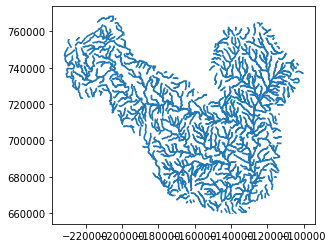

In [41]:
flows3.plot()

In [7]:
%%time
# test split_flows_on_lakes()
from os.path import isfile

ddir = '/home/yxl/test/fim3/tmp/12090205'
odir = '/home/yxl/test/fim3/tmp/test_split_flows'
flows_filename = ddir + '/demDerived_reaches.shp'
lakes_filename = ddir + '/nwm_lakes_proj_subset.gpkg'
flows = gpd.read_file(flows_filename)
if isfile(lakes_filename):
    lakes = gpd.read_file(lakes_filename)
else:
    lakes = None
if not lakes is None:
    # how costly is to simply overlay lakes on all flowlines?
    flows = gpd.overlay(flows, lakes, how='union').explode().reset_index(drop=True)

/srv/sw/conda.evns/fim3/lib/python3.7/site-packages/ipykernel_launcher.py:15: UserWarning: `keep_geom_type=True` in overlay resulted in 4 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  from ipykernel import kernelapp as app


CPU times: user 15.5 s, sys: 37.7 ms, total: 15.5 s
Wall time: 15.7 s


<AxesSubplot:>

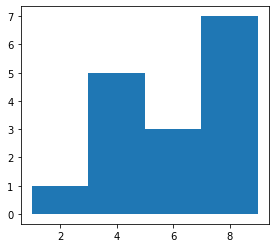

In [44]:
poly1 = shapely.geometry.Polygon([(1,0), (1,1), (3,1), (3,5), (5,5), (5,3), (7,3), (7,7), (9,7), (9,0)])
gds_poly1 = gpd.GeoSeries(poly1)
gds_poly1.plot()

split into  2 parts
[(9.0, 4.0), (10.076923076923077, 4.461538461538462), (11.0, 4.857142857142857), (12.0, 5.285714285714286), (15.0, 6.571428571428571), (16.0, 7.0)]
lakeids [1, 2]


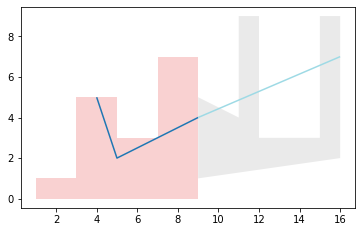

In [12]:
# test 10: inside two polygons
poly1 = shapely.geometry.Polygon([(1,0), (1,1), (3,1), (3,5), (5,5), (5,3), (7,3), (7,7), (9,7), (9,0)])
poly2 = shapely.geometry.Polygon([(9,1), (9,5), (11,4), (11,9), (12, 9), (12, 3), (13, 3), (15, 3), (15,9), (16,9), (16,2)])
line = shapely.geometry.LineString([ (4,5), (5,2), (7,3), (9,4), (16,7)])
splits, lakeids = split_through_polygons(line, [poly1, poly2], [1, 2])
print('split into ', len(splits), 'parts')
print(list(splits[1].coords))
print('lakeids', lakeids)
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='tab20')
gpd.GeoSeries([poly1, poly2]).plot(ax=ax, cmap='Set1', alpha=0.2);

split into  4 parts
[(4.142857142857143, 5.0), (5.0, 2.0), (7.0, 3.0), (9.0, 4.0)]
lakeids [0, 1, 2, 0]


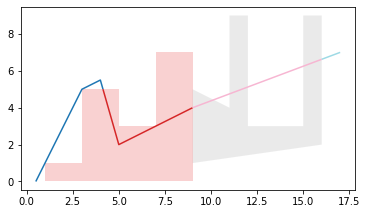

In [13]:
# test 9: line touches polygon, two polygons share border
poly1 = shapely.geometry.Polygon([(1,0), (1,1), (3,1), (3,5), (5,5), (5,3), (7,3), (7,7), (9,7), (9,0)])
poly2 = shapely.geometry.Polygon([(9,1), (9,5), (11,4), (11,9), (12, 9), (12, 3), (13, 3), (15, 3), (15,9), (16,9), (16,2)])
line = shapely.geometry.LineString([(0.5,0), (3,5), (4,5.5), (5,2), (7,3), (9,4), (17,7)])
splits, lakeids = split_through_polygons(line, [poly1, poly2], [1, 2])
print('split into ', len(splits), 'parts')
print(list(splits[1].coords))
print('lakeids', lakeids)
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='tab20')
gpd.GeoSeries([poly1, poly2]).plot(ax=ax, cmap='Set1', alpha=0.2);

split into  5 parts
(4.142857142857143, 5.0) (4.142857142857143, 5.0)
(9.0, 4.0) (9.0, 4.0)
[(4.142857142857143, 5.0), (5.0, 2.0), (7.0, 3.0), (9.0, 4.0)]
lakeids [0, 1, 0, 2, 0]


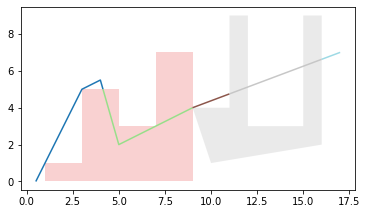

In [14]:
# test 8: line touches polygon, two polygons touch each other
poly1 = shapely.geometry.Polygon([(1,0), (1,1), (3,1), (3,5), (5,5), (5,3), (7,3), (7,7), (9,7), (9,0)])
poly2 = shapely.geometry.Polygon([(10,1), (9,4), (11,4), (11,9), (12, 9), (12, 3), (13, 3), (15, 3), (15,9), (16,9), (16,2)])
line = shapely.geometry.LineString([(0.5,0), (3,5), (4,5.5), (5,2), (7,3), (9,4), (17,7)])
splits, lakeids = split_through_polygons(line, [poly1, poly2], [1, 2])
print('split into ', len(splits), 'parts')
print(splits[0].coords[-1], splits[1].coords[0])
print(splits[1].coords[-1], splits[2].coords[0])
print(list(splits[1].coords))
print('lakeids', lakeids)
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='tab20')
gpd.GeoSeries([poly1, poly2]).plot(ax=ax, cmap='Set1', alpha=0.2);

split into  5 parts
(4.142857142857143, 5.0) (4.142857142857143, 5.0)
(9.0, 4.0) (9.0, 4.0)
[(4.142857142857143, 5.0), (5.0, 2.0), (7.0, 3.0), (9.0, 4.0)]
lakeids [0, 1, 0, 2, 0]


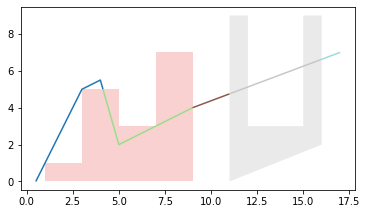

In [15]:
# test 7: line touches polygon, two polygons
poly1 = shapely.geometry.Polygon([(1,0), (1,1), (3,1), (3,5), (5,5), (5,3), (7,3), (7,7), (9,7), (9,0)])
poly2 = shapely.geometry.Polygon([(11,0), (11,9), (12, 9), (12, 3), (13, 3), (15, 3), (15,9), (16,9), (16,2)])
line = shapely.geometry.LineString([(0.5,0), (3,5), (4,5.5), (5,2), (7,3), (9,4), (17,7)])
splits, lakeids = split_through_polygons(line, [poly1, poly2], [1, 2])
print('split into ', len(splits), 'parts')
print(splits[0].coords[-1], splits[1].coords[0])
print(splits[1].coords[-1], splits[2].coords[0])
print(list(splits[1].coords))
print('lakeids', lakeids)
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='tab20')
gpd.GeoSeries([poly1, poly2]).plot(ax=ax, cmap='Set1', alpha=0.2);

identity overlap generated 2 segments
after removing empty geom, there are 2 segments
isoutside of lake: [1, 1, 1, 0, 1, 0, 1]
split into  3 parts
(1.0, 1.0) (1.0, 1.0)
(9.0, 6.4) (9.0, 6.4)
[(1.0, 1.0), (3.0, 5.0), (4.0, 5.5), (4.333333333333333, 5.0), (5.0, 4.0), (7.0, 5.2), (9.0, 6.4)]
TODO: the first segment touches the polygon, should be counted outside


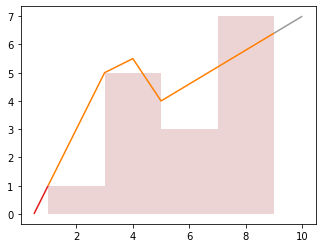

In [45]:
# test 6: line touches polygon
line = shapely.geometry.LineString([(0.5,0), (3,5), (4,5.5), (5,4), (10,7)])
splits = split_through_polygon(line, poly1)
print('split into ', len(splits), 'parts')
print(splits[0].coords[-1], splits[1].coords[0])
print(splits[1].coords[-1], splits[2].coords[0])
print(list(splits[1].coords))
print('TODO: the first segment touches the polygon, should be counted outside')
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='Set1')
gds_poly1.plot(ax=ax, color='brown', alpha=0.2);

identity overlap generated 2 segments
after removing empty geom, there are 2 segments
lakeseq [0, 0, 0, 1, 0, 1, 0]
lakeseq (labeled) [0, 0, 0, 1, 1, 1, 0]
split into  3 parts
(4.333333333333333, 5.0) (4.333333333333333, 5.0)
(9.0, 6.4) (9.0, 6.4)
[(4.333333333333333, 5.0), (5.0, 4.0), (7.0, 5.2), (9.0, 6.4)]
lakeids [0, 1, 0]


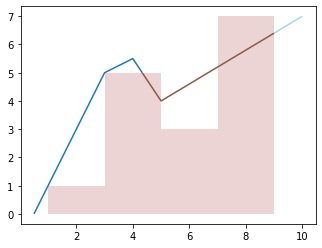

In [113]:
# test 6: line touches polygon
line = shapely.geometry.LineString([(0.5,0), (3,5), (4,5.5), (5,4), (10,7)])
splits, lakeids = split_through_polygons(line, [poly1], [1])
print('split into ', len(splits), 'parts')
print(splits[0].coords[-1], splits[1].coords[0])
print(splits[1].coords[-1], splits[2].coords[0])
print(list(splits[1].coords))
print('lakeids', lakeids)
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='tab20')
gds_poly1.plot(ax=ax, color='brown', alpha=0.2);

,flow,lake,geometry
0,1.0,1.0,"LINESTRING (4.33333 5.00000, 5.00000 4.00000)"
1,1.0,1.0,"LINESTRING (7.00000 5.20000, 9.00000 6.40000)"
2,1.0,NaN,"LINESTRING (0.50000 0.00000, 1.00000 1.00000)"
3,1.0,NaN,"LINESTRING (1.00000 1.00000, 3.00000 5.00000)"
4,1.0,NaN,"LINESTRING (3.00000 5.00000, 4.00000 5.50000, ..."
5,1.0,NaN,"LINESTRING (5.00000 4.00000, 7.00000 5.20000)"
6,1.0,NaN,"LINESTRING (9.00000 6.40000, 10.00000 7.00000)"


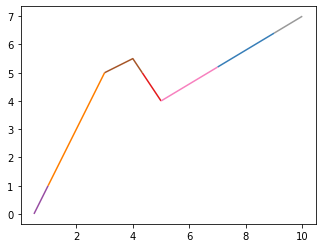

In [79]:
gdf_line = gpd.GeoDataFrame({'geometry': gpd.GeoSeries([line]), 'flow':[1]})
gdf_poly = gpd.GeoDataFrame({'geometry': gpd.GeoSeries([poly1]), 'lake':[1]})
gdf_ol_test = gpd.overlay(gdf_line, gdf_poly, how='identity').explode().reset_index(drop=True)
gdf_ol_test.plot(cmap='Set1')
gdf_ol_test

identity overlap generated 2 segments
after removing empty geom, there are 2 segments
isoutside of lake: [1, 0, 1, 0, 1, 0, 1]
split into  3 parts
(1.0, 0.6666666666666666) (1.0, 0.6666666666666666)
(9.0, 6.5) (9.0, 6.5)


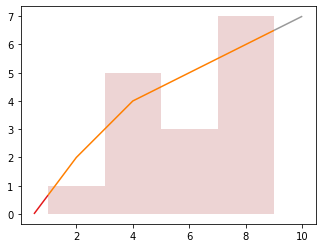

In [114]:
# test 5: 3 parts: out, in, out
line = shapely.geometry.LineString([(0.5,0), (2,2), (4,4), (10,7)])
splits = split_through_polygon(line, poly1)
print('split into ', len(splits), 'parts')
print(splits[0].coords[-1], splits[1].coords[0])
print(splits[1].coords[-1], splits[2].coords[0])
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='Set1')
gds_poly1.plot(ax=ax, color='brown', alpha=0.2);

identity overlap generated 2 segments
after removing empty geom, there are 2 segments
lakeseq [0, 1, 0, 1, 0, 1, 0]
lakeseq (labeled) [0, 1, 1, 1, 1, 1, 0]
split into  3 parts
lakeids [0, 1, 0]
(1.0, 0.6666666666666666) (1.0, 0.6666666666666666)
(9.0, 6.5) (9.0, 6.5)


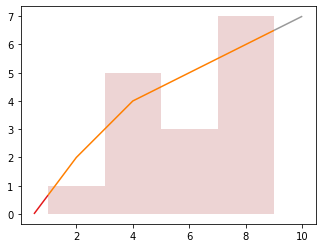

In [115]:
# test 5: 3 parts: out, in, out
line = shapely.geometry.LineString([(0.5,0), (2,2), (4,4), (10,7)])
splits, lakeids = split_through_polygons(line, [poly1], [1])
print('split into ', len(splits), 'parts')
print('lakeids', lakeids)
print(splits[0].coords[-1], splits[1].coords[0])
print(splits[1].coords[-1], splits[2].coords[0])
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='Set1')
gds_poly1.plot(ax=ax, color='brown', alpha=0.2);

identity overlap generated 2 segments
after removing empty geom, there are 2 segments
split into  2 parts
(3.0, 2.7142857142857144) (3.0, 2.7142857142857144)


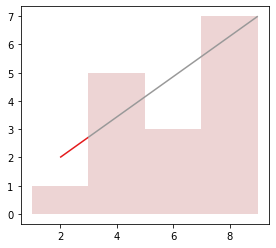

In [65]:
# test 4: 2 parts: out, in
line = shapely.geometry.LineString([(2,2), (9,7)])
splits = split_through_polygon(line, poly1)
print('split into ', len(splits), 'parts')
print(splits[0].coords[-1], splits[1].coords[0])
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='Set1')
gds_poly1.plot(ax=ax, color='brown', alpha=0.2);

identity overlap generated 2 segments
after removing empty geom, there are 2 segments
lakeseq [0, 1, 0, 1]
lakeseq (labeled) [0, 1, 1, 1]
split into  2 parts
lakeids [0, 1]
(3.0, 2.7142857142857144) (3.0, 2.7142857142857144)


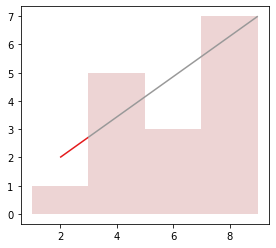

In [116]:
# test 4: 2 parts: out, in
line = shapely.geometry.LineString([(2,2), (9,7)])
splits, lakeids = split_through_polygons(line, [poly1], [1])
print('split into ', len(splits), 'parts')
print('lakeids', lakeids)
print(splits[0].coords[-1], splits[1].coords[0])
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='Set1')
gds_poly1.plot(ax=ax, color='brown', alpha=0.2);

identity overlap generated 2 segments
after removing empty geom, there are 2 segments
split into  2 parts
(8.066666666666666, 7.0) (8.066666666666666, 7.0)


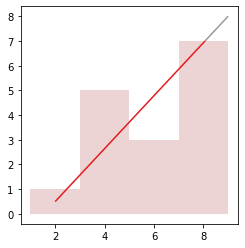

In [64]:
# test 3: 2 parts: in, out
line = shapely.geometry.LineString([(2,0.5), (9,8)])
splits = split_through_polygon(line, poly1)
print('split into ', len(splits), 'parts')
print(splits[0].coords[-1], splits[1].coords[0])
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='Set1')
gds_poly1.plot(ax=ax, color='brown', alpha=0.2);

identity overlap generated 2 segments
after removing empty geom, there are 2 segments
lakeseq [1, 0, 1, 0, 1, 0]
lakeseq (labeled) [1, 1, 1, 1, 1, 0]
split into  2 parts
lakeids [1, 0]
(8.066666666666666, 7.0) (8.066666666666666, 7.0)


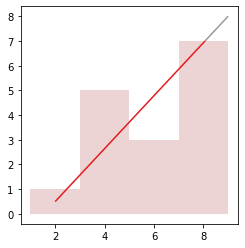

In [119]:
# test 3: 2 parts: in, out
line = shapely.geometry.LineString([(2,0.5), (9,8)])
splits, lakeids = split_through_polygons(line, [poly1], [1])
print('split into ', len(splits), 'parts')
print('lakeids', lakeids)
print(splits[0].coords[-1], splits[1].coords[0])
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='Set1')
gds_poly1.plot(ax=ax, color='brown', alpha=0.2);

In [63]:
# test 2: flowline is inside of polygon
line = shapely.geometry.LineString([(4,1), (9,3)])
splits = split_through_polygon(line, poly1)
splits

identity overlap generated 1 segments
after removing empty geom, there are 1 segments
No need to split


split into  1 parts
lakeids [1]


<AxesSubplot:>

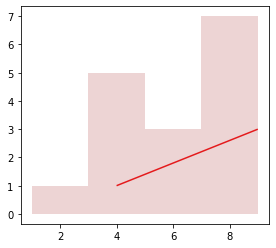

In [34]:
# test 2: flowline is inside of polygon
line = shapely.geometry.LineString([(4,1), (9,3)])
splits, lakeids = split_through_polygons(line, [poly1], [1])
print('split into ', len(splits), 'parts')
print('lakeids', lakeids)
#print(splits[0].coords[-1], splits[1].coords[0])
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='Set1')
gpd.GeoSeries(poly1).plot(ax=ax, color='brown', alpha=0.2)

In [45]:
# test 1: flowline is outside of polygon
line = shapely.geometry.LineString([(0,2), (4,7)])
splits = split_through_polygon(line, poly1)
splits

identity overlap generated 1 segments
after removing empty geom, there are 1 segments
No need to split


split into  1 parts
lakeids [-999]


<AxesSubplot:>

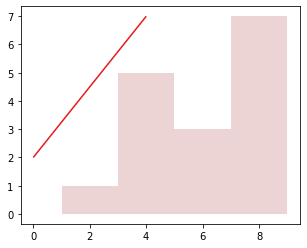

In [33]:
# test 1: flowline is outside of polygon
line = shapely.geometry.LineString([(0,2), (4,7)])
splits, lakeids = split_through_polygons(line, [poly1], [1])
print('split into ', len(splits), 'parts')
print('lakeids', lakeids)
#print(splits[0].coords[-1], splits[1].coords[0])
ax = gpd.GeoSeries([shapely.geometry.LineString(l) for l in splits]).plot(cmap='Set1')
gpd.GeoSeries(poly1).plot(ax=ax, color='brown', alpha=0.2)

In [99]:
flowline.coords[0], flowline.coords[-1]

((-172001.1120827, 809526.272225263), (-171591.488785577, 810889.645288821))

In [129]:
gdf_ol_ident.iloc[ordered_edges[:-1]]['geometry']

0     LINESTRING (-172001.112 809526.272, -171998.05...
8     LINESTRING (-171540.009 810079.569, -171539.52...
1     LINESTRING (-171254.552 810126.102, -171252.17...
9     LINESTRING (-171249.315 810128.480, -171249.11...
2     LINESTRING (-171248.952 810128.644, -171246.06...
10    LINESTRING (-171145.813 810222.613, -171145.18...
3     LINESTRING (-171153.218 810469.716, -171154.35...
11    LINESTRING (-171154.353 810472.249, -171154.35...
4     LINESTRING (-171155.702 810475.256, -171157.41...
12    LINESTRING (-171482.260 810629.810, -171484.49...
5     LINESTRING (-171487.361 810632.673, -171487.55...
13    LINESTRING (-171487.706 810632.867, -171490.61...
6     LINESTRING (-171536.139 810660.053, -171536.46...
14    LINESTRING (-171536.719 810660.379, -171539.52...
7     LINESTRING (-171543.108 810663.964, -171545.63...
Name: geometry, dtype: geometry

In [131]:
[pnt for geom in gdf_ol_ident.iloc[ordered_edges[:-1]]['geometry'] for pnt in geom.coords[:2]]

[(-172001.1120827, 809526.272225263),
 (-171998.055192423, 809529.32911554),
 (-171540.00902675185, 810079.569365406),
 (-171539.521650868, 810079.569365406),
 (-171254.55151342077, 810126.1020612442),
 (-171252.173964826, 810128.479609839),
 (-171249.3151217028, 810128.479609839),
 (-171249.117074549, 810128.479609839),
 (-171248.95236920775, 810128.6443151803),
 (-171246.060184272, 810131.536500116),
 (-171145.8129970666, 810222.6130164904),
 (-171145.18280513, 810223.243208427),
 (-171153.21825729904, 810469.716102205),
 (-171154.353475961, 810470.851320867),
 (-171154.353475961, 810472.2486905429),
 (-171154.353475961, 810473.908211144),
 (-171155.7016651973, 810475.2564003803),
 (-171157.410366238, 810476.965101421),
 (-171482.25993562327, 810629.809615273),
 (-171484.497625881, 810629.809615273),
 (-171487.36086074126, 810632.6728501333),
 (-171487.554516158, 810632.86650555),
 (-171487.70586275044, 810632.86650555),
 (-171490.611406435, 810632.86650555),
 (-171536.13918401618, 8

In [16]:
#gdf_ol_union = gpd.overlay(gdf_flow, gdf_lake, how='union', keep_geom_type=False)
gdf_ol_union = gpd.overlay(gdf_flow, gdf_lake, how='union', keep_geom_type=True) # default
gdf_ol_union

,flow,lake,geometry
0,1.0,1.0,"MULTILINESTRING ((-172001.112 809526.272, -171..."
1,1.0,NaN,"MULTILINESTRING ((-171540.009 810079.569, -171..."


<AxesSubplot:>

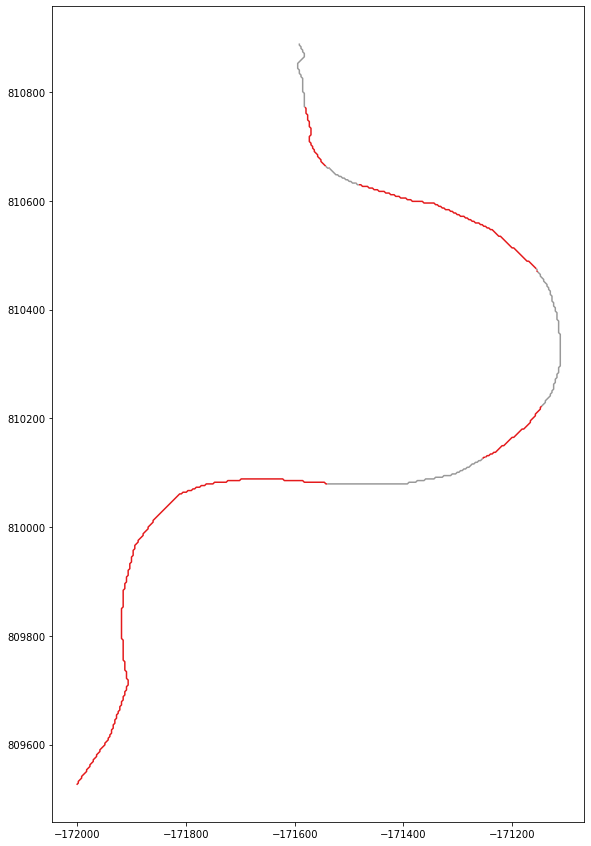

In [17]:
gdf_ol_union.plot(cmap='Set1', figsize=(20,15))

In [18]:
gdf_ol_union2 = gdf_ol_union.explode().reset_index(drop=True)
gdf_ol_union2

,flow,lake,geometry
0,1.0,1.0,"LINESTRING (-172001.112 809526.272, -171998.05..."
1,1.0,1.0,"LINESTRING (-171254.552 810126.102, -171252.17..."
2,1.0,1.0,"LINESTRING (-171248.952 810128.644, -171246.06..."
3,1.0,1.0,"LINESTRING (-171153.218 810469.716, -171154.35..."
4,1.0,1.0,"LINESTRING (-171155.702 810475.256, -171157.41..."
5,1.0,1.0,"LINESTRING (-171487.361 810632.673, -171487.55..."
6,1.0,1.0,"LINESTRING (-171536.139 810660.053, -171536.46..."
7,1.0,1.0,"LINESTRING (-171543.108 810663.964, -171545.63..."
8,1.0,NaN,"LINESTRING (-171540.009 810079.569, -171539.52..."
9,1.0,NaN,"LINESTRING (-171249.315 810128.480, -171249.11..."


In [19]:
gdf_ol_union3 = gdf_ol_union2.loc[~gdf_ol_union2.is_empty,:]
gdf_ol_union3

,flow,lake,geometry
0,1.0,1.0,"LINESTRING (-172001.112 809526.272, -171998.05..."
1,1.0,1.0,"LINESTRING (-171254.552 810126.102, -171252.17..."
2,1.0,1.0,"LINESTRING (-171248.952 810128.644, -171246.06..."
3,1.0,1.0,"LINESTRING (-171153.218 810469.716, -171154.35..."
4,1.0,1.0,"LINESTRING (-171155.702 810475.256, -171157.41..."
5,1.0,1.0,"LINESTRING (-171487.361 810632.673, -171487.55..."
6,1.0,1.0,"LINESTRING (-171536.139 810660.053, -171536.46..."
7,1.0,1.0,"LINESTRING (-171543.108 810663.964, -171545.63..."
8,1.0,NaN,"LINESTRING (-171540.009 810079.569, -171539.52..."
9,1.0,NaN,"LINESTRING (-171249.315 810128.480, -171249.11..."


In [20]:
for i,geom in enumerate(gdf_ol_union3.geometry):
    print(i, type(geom))

0 <class 'shapely.geometry.linestring.LineString'>
1 <class 'shapely.geometry.linestring.LineString'>
2 <class 'shapely.geometry.linestring.LineString'>
3 <class 'shapely.geometry.linestring.LineString'>
4 <class 'shapely.geometry.linestring.LineString'>
5 <class 'shapely.geometry.linestring.LineString'>
6 <class 'shapely.geometry.linestring.LineString'>
7 <class 'shapely.geometry.linestring.LineString'>
8 <class 'shapely.geometry.linestring.LineString'>
9 <class 'shapely.geometry.linestring.LineString'>
10 <class 'shapely.geometry.linestring.LineString'>
11 <class 'shapely.geometry.linestring.LineString'>
12 <class 'shapely.geometry.linestring.LineString'>
13 <class 'shapely.geometry.linestring.LineString'>
14 <class 'shapely.geometry.linestring.LineString'>
15 <class 'shapely.geometry.linestring.LineString'>
